# Part 3: Conducting the Analysis
## 3.1 Exploratory Data Aanalysis

In [6]:
# importing libraries
# Data Handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# NLP
import re
import nltk
from nltk.corpus import stopwords

# Word Cloud
from wordcloud import WordCloud

nltk.download('stopwords')
print("libraries imported successfully")

libraries imported successfully


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\charl\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [7]:
# Loading the dataset

# Loading only the columns needed for the project to reduce memory usage
columns_needed = ['Id','ProductId', 'UserId', 'Score', 'Summary', 'Text']

df = pd.read_csv("C:\\Users\\charl\\CrossDevice\\Thato's Tab S9 FE (1)\\storage\\Download\\Reviews.csv.zip", usecols=columns_needed)

# Displaying the dataset information
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   Id         568454 non-null  int64 
 1   ProductId  568454 non-null  object
 2   UserId     568454 non-null  object
 3   Score      568454 non-null  int64 
 4   Summary    568427 non-null  object
 5   Text       568454 non-null  object
dtypes: int64(2), object(4)
memory usage: 26.0+ MB
None


,Id,ProductId,UserId,Score,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,5,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,1,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,4,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,2,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,5,Great taffy,Great taffy at a great price. There was a wid...


In [8]:
# Displaying data types
print("Column names:", df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("data_type"))

Column names: ['Id', 'ProductId', 'UserId', 'Score', 'Summary', 'Text']

Data types:


,data_type
Id,int64
ProductId,object
UserId,object
Score,int64
Summary,object
Text,object


In [9]:
# Checking for missing values
df.isnull().sum()

Id            0
ProductId     0
UserId        0
Score         0
Summary      27
Text          0
dtype: int64

In [10]:
# Removing missing values
df = df.dropna(subset=['Text'])
print("Missing values were removed")

Missing values were removed


In [11]:
# Removing duplicates
df = df.drop_duplicates(subset=['UserId', 'ProductId', 'Text'])
print("Duplicates have been removed successfully")

Duplicates have been removed successfully


In [12]:
rows_before = len(df)

# Remove records without the essential text or rating fields.
df = df.dropna(subset=["Text", "Score"]).copy()
df = df[df["Score"].isin([1, 2, 3, 4, 5])].copy()

# Remove exact duplicate rows.
df = df.drop_duplicates()

# Standardise text fields and handle missing summaries.
df["Text"] = df["Text"].astype(str).str.strip()
df["Summary"] = df["Summary"].fillna("").astype(str).str.strip()

# Remove rows where review text is empty after trimming.
df = df[df["Text"].str.len() > 0].copy()

print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Rows removed:         {rows_before - len(df):,}")
print("\nMissing values after cleaning:")
display(df[["Text", "Score", "Summary"]].isna().sum().to_frame("missing_count"))

Rows before cleaning: 567,145
Rows after cleaning:  567,145
Rows removed:         0

Missing values after cleaning:


,missing_count
Text,0
Score,0
Summary,0


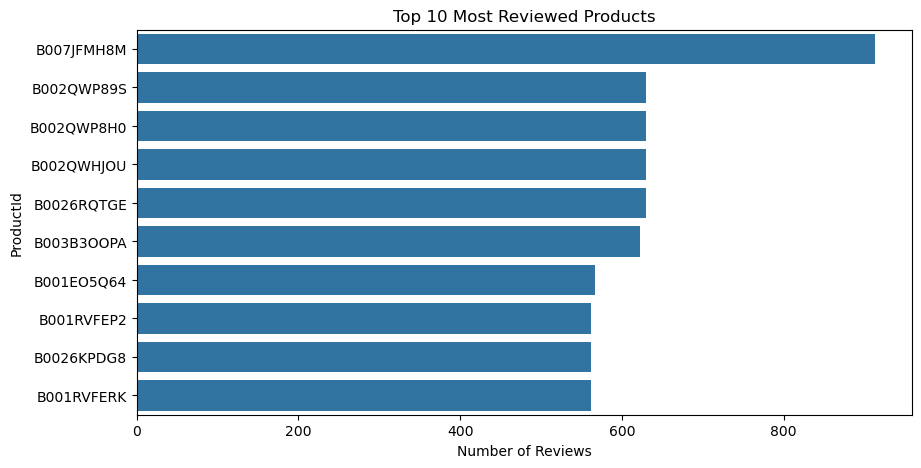

In [46]:
top_products = df['ProductId'].value_counts().head(10)
plt.figure(figsize=(10,5))
sns.barplot(
    x=top_products.values,
    y=top_products.index)
plt.title("Top 10 Most Reviewed Products")
plt.xlabel("Number of Reviews")
plt.show()

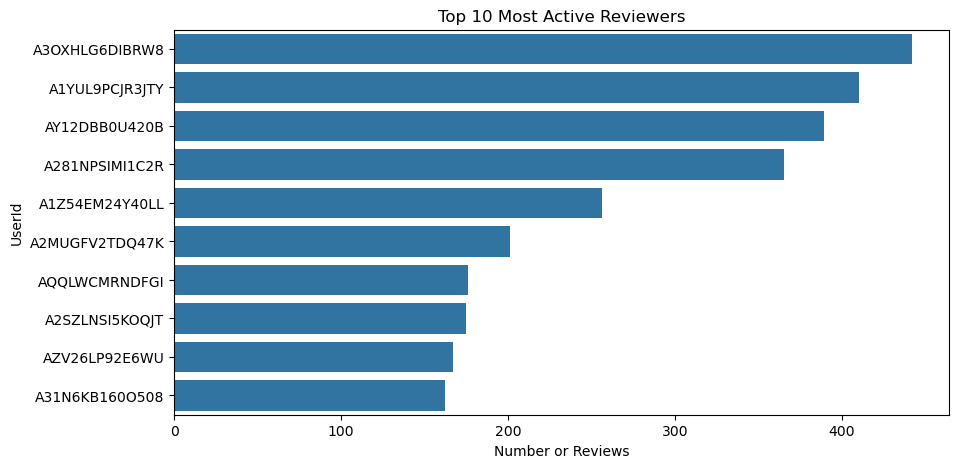

In [47]:
# Active Reviewers
top_users = df['UserId'].value_counts().head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=top_users.values, y=top_users.index)
plt.title("Top 10 Most Active Reviewers")
plt.xlabel("Number or Reviews")
plt.show()

In [25]:
# Creating Sentiment lables
df['Sentiment'] = df['Score'].apply(lambda x: 1 if x >= 4 else 0)

# positive reviews: 4 or 5 stars
# negative reviews: 1,2 or 3 stars

In [13]:
# Text cleaning
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

print("lowercasing,punctuation removal,number removal and stopword removal performed successfully") 

lowercasing,punctuation removal,number removal and stopword removal performed successfully


In [15]:
df['clean_text'] = df['Text'].apply(clean_text)
print("text cleaned successfully and now ready for machine learning")

text cleaned successfully and now ready for machine learning


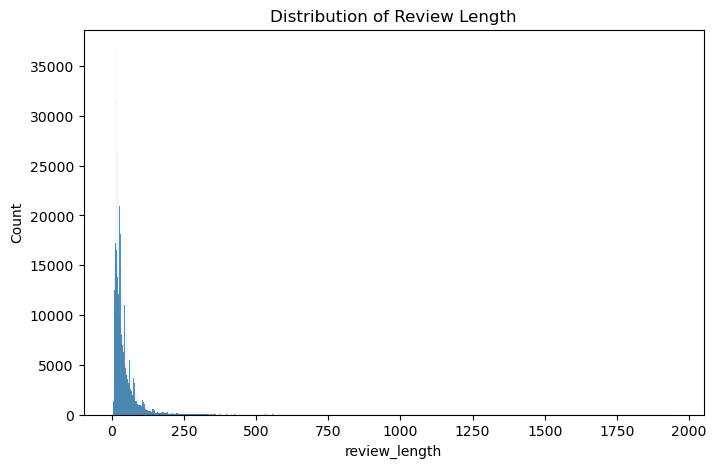

In [16]:
# Reviewing length analysis
df['review_length'] = df['clean_text'].apply(lambda x: len(x.split()))

plt.figure(figsize=(8,5))
sns.histplot(df['review_length'])
plt.title('Distribution of Review Length')
plt.show()

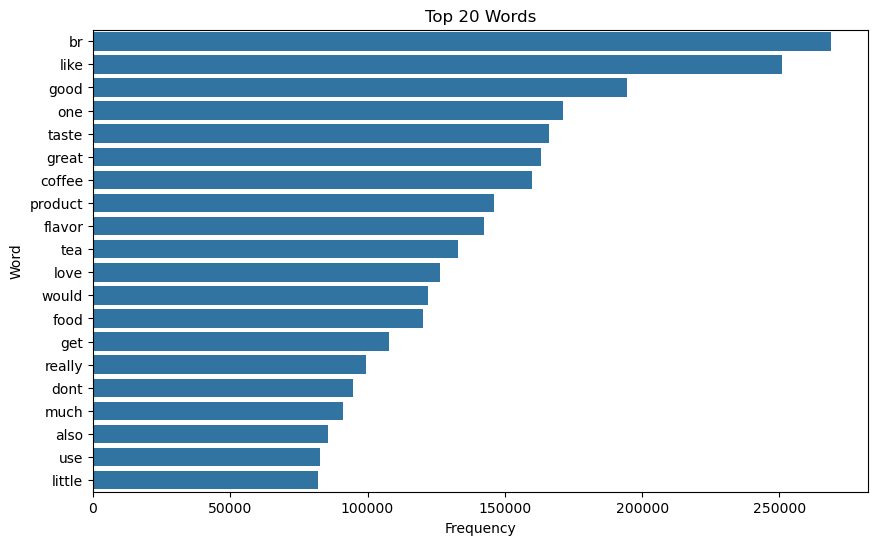

In [17]:
# Most frequent words
from collections import Counter

all_words = " ".join(df['clean_text'])
word_freq = Counter(all_words.split())
top_words = pd.DataFrame(word_freq.most_common(20), columns=['Word', 'Frequency'])
plt.figure(figsize=(10,6))
sns.barplot(data=top_words,
            x='Frequency',
            y='Word')
plt.title('Top 20 Words')
plt.show()


In [2]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

In [20]:
all_words = " ".join(df['clean_text'].astype(str))

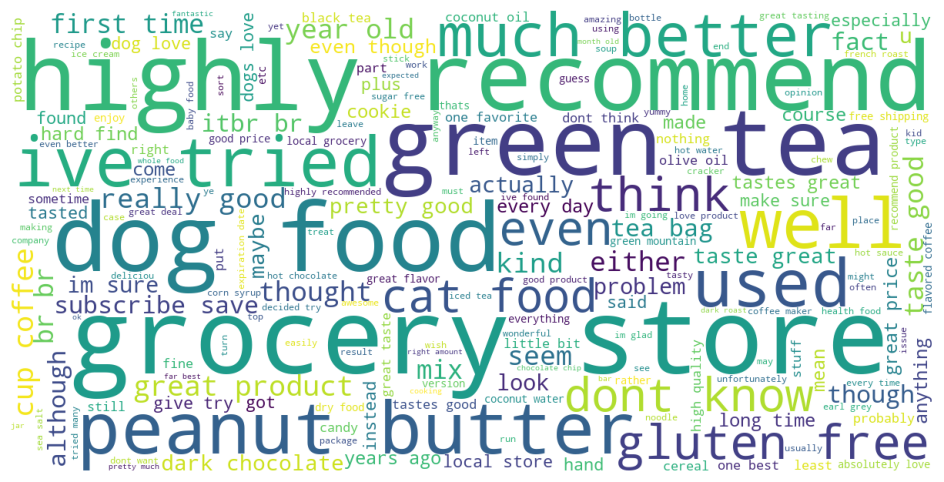

In [18]:
# Word Cloud
wordcloud = WordCloud(width=1200, height=600, background_color='white').generate(all_words)

plt.figure(figsize=(12,6))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()

# Feature Engineering

In [27]:
# TF-IDF Vectorization
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X = tfidf.fit_transform(df['clean_text'])
y = df['Sentiment']

In [30]:
# Topic modelling
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

# Creating TF-IDF matrix for topic modelling
tfidf_nmf = TfidfVectorizer(max_features=5000, stop_words='english')
X_nmf = tfidf_nmf.fit_transform(df['clean_text'])

# Creating the NMF model
nmf_model = NMF(n_components=5, random_state=42)

# Fit model
nmf_model.fit(X_nmf)
                            

,n_components,5
,init,None
,solver,'cd'
,beta_loss,'frobenius'
,tol,0.0001
,max_iter,200
,random_state,42
,alpha_W,0.0
,alpha_H,'same'
,l1_ratio,0.0
,verbose,0


In [29]:
# Getting feature names
feature_names = tfidf.get_feature_names_out()

# Displaying keywords for each topic
for topic_idx, topic in enumerate(nmf_model.components_):
    print(f"\nTopic {topic_idx + 1}")
    top_words = [feature_names[i] for i in topic.argsort()[:-11:-1]]
    print(top_words)



Topic 1
['lasting', 'br good', 'theyd', 'give try', 'fits bill', 'chicken flavor', 'quart', 'donuts', 'tea would', 'chewy']

Topic 2
['coffe', 'cup water', 'symptoms', 'bought one', 'fits bill', 'rinse', 'lasting', 'isnt', 'interested', 'bold coffee']

Topic 3
['think ill', 'good job', 'thisbr', 'drinkers', 'fits bill', 'batches', 'high', 'body', 'cup water', 'stuff']

Topic 4
['flax', 'dont taste', 'dont use', 'two cats', 'cant tell', 'like flavored', 'capsules', 'eat much', 'twist', 'checking']

Topic 5
['good flavor', 'pounds', 'pop chips', 'amazon would', 'like drinking', 'bull', 'notbr', 'surprised', 'toxic', 'sister']


In [48]:
# Displaying the most important terms for every NMF topic
feature_names = tfidf_nmf.get_feature_names_out()
number_of_top_words = 10
topic_results = []
for topic_number, topic_weights in enumerate(nmf_model.components_):
    top_indices = topic_weights.argsort()[-number_of_top_words:][::-1]
    top_words = [feature_names[index] for index in top_indices]

    topic_results.append({"Topic":topic_number + 1, "Top words": ", ".join(top_words)})
topic_table = pd.DataFrame(topic_results)
topic_table

,Topic,Top words
0,1,"like, br, taste, good, flavor, chocolate, real..."
1,2,"coffee, cup, strong, bold, flavor, roast, like..."
2,3,"tea, green, teas, drink, flavor, bags, iced, b..."
3,4,"food, dog, dogs, treats, cat, loves, cats, eat..."
4,5,"great, product, price, amazon, love, buy, orde..."


In [32]:
# Interpreting topics
topics = {
    1: "Taste and Flavour",
    2: "Packaging and Delivery",
    3: "Coffee Products",
    4: "Price and Value",
    5: "Tea Products"}
for topic_num, theme in topics.items():
    print(f"Topic {topic_num}: {theme}")

Topic 1: Taste and Flavour
Topic 2: Packaging and Delivery
Topic 3: Coffee Products
Topic 4: Price and Value
Topic 5: Tea Products


# 3.3 Model Training


In [34]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42)
print("Train test split was successful")

Train test split was successful


In [35]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [36]:
# Generating predictions
predictions = model.predict(X_test)
print("Predictions generated successfully")

Predictions generated successfully


# Part 4: Model Evaluation and Improvement

In [38]:
# Model Evaluation
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report)
print("Accuracy:", accuracy_score(y_test,predictions))
print("Precision:", precision_score(y_test,predictions))
print("Recall:", recall_score(y_test,predictions))
print("f1:", f1_score(y_test,predictions))
print(classification_report(y_test,predictions))


Accuracy: 0.8939689144751343
Precision: 0.9119170425362022
Recall: 0.9562772277227722
f1: 0.9335704698727969
              precision    recall  f1-score   support

           0       0.81      0.67      0.74     25054
           1       0.91      0.96      0.93     88375

    accuracy                           0.89    113429
   macro avg       0.86      0.82      0.84    113429
weighted avg       0.89      0.89      0.89    113429



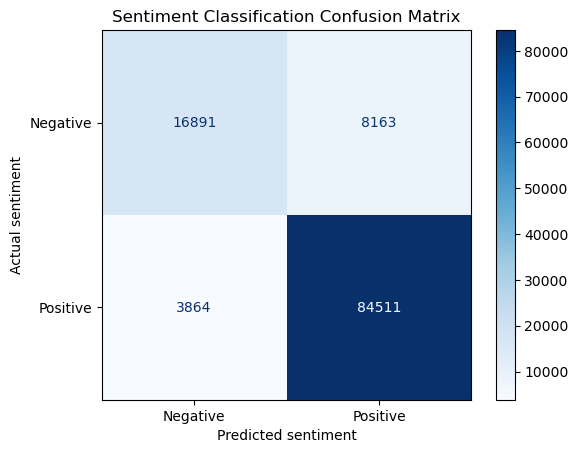

In [70]:
# Confusion Matrix
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    values_format="d")
plt.title("Sentiment Classification Confusion Matrix")
plt.xlabel("Predicted sentiment")
plt.ylabel("Actual sentiment")
plt.show()

## 4.2 Model Improvement

In [43]:
# Improvements Applied
tfidf = TfidfVectorizer( max_features=10000, ngram_range=(1,2))
improved_model = LogisticRegression(max_iter=2000, C=1.5)